# Exploración de datos — Caso 1: e-commerce chileno

**Objetivo**: perfilado y análisis de calidad de los 4 datasets crudos,
detección de anomalías y propuesta de etiqueta derivada para detección
de fraude (el caso **no trae columna de fraude/etiqueta**).

**Datasets** (en `../datos/crudos/`):

- `usuarios.csv`: clientes
- `transacciones.csv`: líneas de pedido
- `productos.csv`: catálogo
- `clickstream.csv`: eventos de navegación

**Cómo ejecutar**: desde la carpeta `notebooks/` (las rutas son
relativas: `../datos`). Requiere **pandas ≥ 2.2** (se usa
`resample("ME")` y `to_datetime(format="mixed")`).

**Convenciones**:

- `raw`: datos crudos, **intactos**, todo leído como texto
  (`dtype=str`) para no perder el formato original.
- `senales`: señales y etiqueta derivada `sospechoso` (sección 7).
- `clean`: versión normalizada con marcas de calidad (sección 9).
- Las cifras citadas en el markdown están respaldadas por salidas
  de código de este mismo notebook.


In [1]:
from pathlib import Path
import re
import unicodedata
import warnings

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Carpeta de datos crudos. El notebook debe ejecutarse desde notebooks/.
DATOS = Path("../datos")
assert DATOS.exists(), (
    f"No se encontró la carpeta de datos en {DATOS.resolve()}. "
    "Ejecuta el notebook desde la carpeta notebooks/."
)


## 1. Carga y perfilado

Lectura de los 4 CSV y perfilado por columna: nulos, %, únicos y
una muestra. Todo se lee como texto (`dtype=str`) para no perder el
formato original (fechas con varios formatos, montos con "$" y
punto de miles, booleanos escritos de distintas formas).


In [2]:
archivos = sorted(DATOS.rglob("*.csv"))
print([a.name for a in archivos])
assert len(archivos) == 4, f"Se esperaban 4 CSV, se encontraron {len(archivos)}"


['clickstream.csv', 'productos.csv', 'transacciones.csv', 'usuarios.csv']


In [3]:
# raw: datos crudos, intactos. Toda transformación vive en clean (sección 9).
raw = {a.stem: pd.read_csv(a, dtype=str, keep_default_na=True) for a in archivos}

for nombre, df in raw.items():
    print(f"\n=== {nombre} ===")
    display(df.head(5))



=== clickstream ===


,evento_id,sesion_id,usuario_id,timestamp,tipo_evento,sku,termino_busqueda,dispositivo,user_agent
0,E1005629,S201123,NaN,2025-03-22 00:56:38,vista,NX-11438,NaN,movil,Mozilla/5.0 (iPhone; CPU iPhone OS 17_5 like M...
1,E1004553,S200898,NaN,2026-05-09T16:19:23Z,vista,NX-11037,NaN,escritorio,Mozilla/5.0 (Linux; Android 14; SM-A546E) Appl...
2,E1023204,S204770,U100651,2025-10-08T06:37:26Z,busqueda,NaN,tarjeta de video,movil,Mozilla/5.0 (iPhone; CPU iPhone OS 17_5 like M...
3,E1014010,S202845,NaN,2025-02-25T16:03:32Z,vista,NX-10191,NaN,movil,Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:1...
4,E1006093,S201218,U100072,2025-04-12 12:34:30,clic,NX-10539,NaN,escritorio,Mozilla/5.0 (iPhone; CPU iPhone OS 17_5 like M...



=== productos ===


,sku,nombre,categoria,marca,precio_lista,costo,stock,activo,fecha_alta
0,NX-10637,Gigabyte Notebook X,Notebooks,Gigabyte,19666,12193,5,0,22-11-2024
1,NX-10785,Kingston Monitore Lite,Monitores,Kingston,21993,13636,-9,0,2024-01-29
2,NX-10647,Dell Rede V2,Redes,Dell,37619,23324,2,Si,2020-07-06
3,NX-10699,Asus Notebook Pro,notebooks,Asus,35216,21834,2,true,2022-11-11
4,NX-11243,Acer Periferico Air,perifericos,Acer,$19.929,12356,48,Si,03-04-2020



=== transacciones ===


,pedido_id,linea,usuario_id,sku,fecha,cantidad,precio_unitario,descuento,total,canal,estado
0,P503740,1,U102528,NX-10196,2024-09-12 02:24:42,1,22335,0,22335,tienda,pagado
1,P515260,1,U100628,NX-11440,2024-12-03 03:09:12,1,20968,4193,16775,movil,pagado
2,P512487,1,U103839,NX-11440,2026-07-09 16:12:33,3,19573,11743,46976,app,pagado
3,P509155,1,U102782,NX-10075,2025-04-05 00:30:34,1,64969,0,64969,web,devuelto
4,P511269,1,U103671,NX-10851,2025-11-20 08:50:37,1,8311,NaN,8311,app,pagado



=== usuarios ===


,usuario_id,fecha_registro,region,comuna,canal_captacion,email_valido,acepta_marketing,edad
0,U103808,2023-04-19,COQUIMBO,Antofagasta,organico,true,NaN,40
1,U103458,2022-05-03,Valparaiso,Iquique,organico,false,NaN,0
2,U103013,10/01/2022,Biobío,Temuco,pagado,NaN,0,48
3,U100649,2025-06-04,Antofagasta,La Florida,organico,false,1,65
4,U102490,2024-12-07,metropolitana,Maipú,UNKNOWN,true,1,66


In [4]:
def perfil_columnas(df):
    return pd.DataFrame({
        "nulos": df.isna().sum(),
        "%nulos": (df.isna().mean() * 100).round(1),
        "unicos": df.nunique(),
        "ejemplo": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })

resumen = []
for nombre, df in raw.items():
    resumen.append({
        "archivo": nombre, "filas": len(df), "columnas": df.shape[1],
        "nulos_totales": int(df.isna().sum().sum()),
        "filas_duplicadas": int(df.duplicated().sum()),
    })
    print(f"\n--- {nombre} ---")
    print(perfil_columnas(df))
display(pd.DataFrame(resumen))



--- clickstream ---
                  nulos  %nulos  unicos                                            ejemplo
evento_id             0     0.0   29077                                           E1005629
sesion_id             0     0.0    6000                                            S201123
usuario_id        17653    60.2    2411                                            U100651
timestamp             0     0.0   29060                                2025-03-22 00:56:38
tipo_evento           0     0.0      14                                              vista
sku                6289    21.4    1439                                           NX-11438
termino_busqueda  23051    78.6      16                                   tarjeta de video
dispositivo           0     0.0       7                                              movil
user_agent            0     0.0      11  Mozilla/5.0 (iPhone; CPU iPhone OS 17_5 like M...

--- productos ---
              nulos  %nulos  unicos              e


--- transacciones ---
                 nulos  %nulos  unicos              ejemplo
pedido_id            0     0.0   17146              P503740
linea                0     0.0       4                    1
usuario_id          93     0.4    4224              U102528
sku                  0     0.0    1201             NX-10196
fecha                0     0.0   19165  2024-09-12 02:24:42
cantidad             0     0.0       9                    1
precio_unitario    440     2.0   17446                22335
descuento         8642    39.0    4884                    0
total                0     0.0   18753                22335
canal                0     0.0       7               tienda
estado               0     0.0       4               pagado

--- usuarios ---
                  nulos  %nulos  unicos      ejemplo
usuario_id            0     0.0    4000      U103808
fecha_registro        0     0.0    2833   2023-04-19
region                0     0.0      33     COQUIMBO
comuna              304    

,archivo,filas,columnas,nulos_totales,filas_duplicadas
0,clickstream,29340,9,46993,263
1,productos,1531,9,227,31
2,transacciones,22187,11,9175,186
3,usuarios,4026,8,1487,26


## 2. Claves: unicidad y duplicados por clave

Una clave candidata es una columna que se llama exactamente `id`,
empieza con `id_` o termina en `_id`. El regex `^id$|^id_|_id$` es
estricto: no captura columnas como `idioma`.


In [5]:
def candidatas_clave(df):
    return [c for c in df.columns if re.search(r"^id$|^id_|_id$", c.lower())]

for nombre, df in raw.items():
    for c in candidatas_clave(df):
        dup = df[c].dropna().duplicated().sum()
        print(f"{nombre}.{c}: {df[c].nunique()} únicos, "
              f"{dup} repetidos, {df[c].isna().sum()} nulos")


clickstream.evento_id: 29077 únicos, 263 repetidos, 0 nulos
clickstream.sesion_id: 6000 únicos, 23340 repetidos, 0 nulos
clickstream.usuario_id: 2411 únicos, 9276 repetidos, 17653 nulos
transacciones.pedido_id: 17146 únicos, 5041 repetidos, 0 nulos
transacciones.usuario_id: 4224 únicos, 17870 repetidos, 93 nulos
usuarios.usuario_id: 4000 únicos, 26 repetidos, 0 nulos


## 3. Variantes de texto

Columnas categóricas con pocos valores únicos pero escritas de forma
inconsistente (mayúsculas, tildes, espacios, sinónimos en inglés).
Normalizar es un paso previo a cualquier agrupación o join.


In [6]:
def variantes(df, max_unicos=60):
    for c in df.columns:
        s = df[c].dropna()
        if 1 < s.nunique() <= max_unicos:
            norm = s.str.strip().str.lower()
            if s.nunique() != norm.nunique():
                print(f"  {c}: {s.nunique()} crudos -> {norm.nunique()} normalizados")
                print("   ", sorted(s.unique())[:15])

for nombre, df in raw.items():
    print(f"\n--- {nombre} ---")
    variantes(df)



--- clickstream ---

  tipo_evento: 14 crudos -> 8 normalizados
    ['AGREGAR_CARRITO', 'BUSQUEDA', 'CLIC', 'Clic ', 'VISTA', 'Vista', 'add_to_cart', 'agregar_carrito', 'busqueda', 'clic', 'click', 'search', 'view', 'vista']
  dispositivo: 7 crudos -> 5 normalizados
    ['Escritorio', 'MOVIL', 'desktop', 'escritorio', 'mobile', 'movil', 'tablet']



--- productos ---
  categoria: 20 crudos -> 12 normalizados
    ['Almacenamiento', 'Audio', 'COMPONENTES', 'Cables', 'Cables y adaptadores', 'Componentes', 'Gaming', 'Monitores', 'NOTEBOOKS', 'Notebooks', 'Notebooks ', 'PERIFERICOS', 'Perifericos', 'Periféricos', 'Redes']
  activo: 7 crudos -> 6 normalizados
    ['0', '1', 'No', 'Si', 'TRUE', 'false', 'true']

--- transacciones ---
  canal: 7 crudos -> 4 normalizados
    ['App', 'TIENDA', 'WEB', 'app', 'movil', 'tienda', 'web']

--- usuarios ---
  region: 33 crudos -> 25 normalizados
    ['Antofagasta', 'Araucania', 'Araucanía', 'BIOBIO', 'Bio-Bio', 'Biobio', 'Biobío', 'Bío Bío', 'COQUIMBO', 'Coquimbo', 'Del Maule', 'LOS LAGOS', 'La Araucania', "Libertador B. O'Higgins", 'Los Lagos']


## 4. Fechas y montos mal formados

Intenta convertir y mira QUÉ falla (no solo cuántos).

- Las fechas vienen en **4 formatos** (ISO, ISO con zona horaria,
  `dd/mm/aaaa`, `dd-mm-aaaa`, con/sin hora). El parser ingenuo con
  `dayfirst=True` falla en 13k–16k registros por columna; el parser
  multi-formato (`format="mixed"`) parsea el **100%**.
- Los montos vienen en **formato chileno**: `$18.703` = 18703 (el
  punto es separador de MILES, no decimal). Un parser ingenuo los
  leería como decimales y rompería la verificación de totales.


In [7]:
def intentar_fecha(s):
    """Parser ingenuo: falla con formatos mezclados en una misma columna."""
    return pd.to_datetime(s, errors="coerce", dayfirst=True)

def intentar_fecha_mixto(s):
    """Parser multi-formato: acepta ISO, ISO con Z/offset y dd/mm/aaaa
    (con/sin hora). Todo queda en UTC: los naive se interpretan como UTC.
    Si necesitas hora local de Chile, usa .dt.tz_convert("America/Santiago")."""
    return pd.to_datetime(s, errors="coerce", dayfirst=True, format="mixed", utc=True)

def intentar_monto(s):
    """Parser para montos CLP: "$18.703" -> 18703 (el punto es separador
    de MILES). Quita todo lo que no sea dígito o signo negativo."""
    # Validación: detecta valores con posible patrón decimal (ej. "18.5",
    # "18,5"), que este parser corrompería ("18.5" -> "185"). Los reporta.
    patron_decimal = s.str.match(r"^\s*-?\$?\d+[.,]\d{1,2}\s*$", na=False)
    if patron_decimal.any():
        print(f"  ⚠ {int(patron_decimal.sum())} valores con posible decimal: "
              f"{s[patron_decimal].head(5).tolist()}")
    limpio = s.str.replace(r"[^\d\-]", "", regex=True)
    return pd.to_numeric(limpio, errors="coerce")

print("=== Parser ingenuo (dayfirst=True): qué falla ===")
with warnings.catch_warnings():
    # El aviso de pandas sobre dayfirst es esperado aquí: el punto de esta
    # sección es justamente mostrar lo que falla con el parser ingenuo.
    warnings.simplefilter("ignore", UserWarning)
    for nombre, df in raw.items():
        for c in df.columns:
            n = c.lower()
            if any(k in n for k in ("fecha", "date", "hora", "timestamp")):
                malas = df[c].notna() & intentar_fecha(df[c]).isna()
                print(f"{nombre}.{c} FECHA no parseable: {malas.sum()}  ej: {df.loc[malas, c].head(5).tolist()}")
            if any(k in n for k in ("monto", "amount", "valor", "precio", "total", "costo")):
                malas = df[c].notna() & intentar_monto(df[c]).isna()
                print(f"{nombre}.{c} MONTO no parseable: {malas.sum()}  ej: {df.loc[malas, c].head(5).tolist()}")

print("\n=== Verificación con parser multi-formato ===")
for nombre, df in raw.items():
    for c in df.columns:
        if any(k in c.lower() for k in ("fecha", "date", "hora", "timestamp")):
            print(f"{nombre}.{c}: NaT con parser mixto: {intentar_fecha_mixto(df[c]).isna().sum()}")


=== Parser ingenuo (dayfirst=True): qué falla ===
clickstream.timestamp FECHA no parseable: 13256  ej: ['2026-05-09T16:19:23Z', '2025-10-08T06:37:26Z', '2025-02-25T16:03:32Z', '2026-04-02 21:25:40-03:00', '27/02/2026 17:01']
productos.precio_lista MONTO no parseable: 0  ej: []
productos.costo MONTO no parseable: 0  ej: []
productos.fecha_alta FECHA no parseable: 1359  ej: ['2024-01-29', '2020-07-06', '2022-11-11', '15/09/2021', '2023-04-09']
transacciones.fecha FECHA no parseable: 16071  ej: ['2025-11-20 08:50:37', '2025-07-23 08:17:09', '2025-05-14 23:44:12', '2025-12-15 04:41:21', '11/10/2025 14:25']


transacciones.precio_unitario MONTO no parseable: 0  ej: []


transacciones.total MONTO no parseable: 0  ej: []
usuarios.fecha_registro FECHA no parseable: 1206  ej: ['10/01/2022', '23/01/2019', '17/05/2021', '01-09-2024', '26-12-2021']

=== Verificación con parser multi-formato ===


clickstream.timestamp: NaT con parser mixto: 0
productos.fecha_alta: NaT con parser mixto: 0


transacciones.fecha: NaT con parser mixto: 0
usuarios.fecha_registro: NaT con parser mixto: 0


## 5. Numéricas: rangos, negativos y outliers

En fraude, un outlier puede ser la señal. Marcar, no borrar a ciegas.
`edad` se parsea con `pd.to_numeric` (no es un monto CLP).


In [8]:
for nombre, df in raw.items():
    for c in df.columns:
        if any(k in c.lower() for k in ("monto", "amount", "valor", "edad", "age", "score", "cantidad")):
            if any(k in c.lower() for k in ("edad", "age")):
                v = pd.to_numeric(df[c], errors="coerce")
            else:
                v = intentar_monto(df[c])
            if v.notna().any():
                q1, q3 = v.quantile([.25, .75])
                iqr = q3 - q1
                fuera = ((v < q1 - 3 * iqr) | (v > q3 + 3 * iqr)).sum()
                print(f"{nombre}.{c}: min={v.min()}, mediana={v.median()}, max={v.max()}, "
                      f"negativos={(v < 0).sum()}, ceros={(v == 0).sum()}, extremos(3*IQR)={fuera}")


transacciones.cantidad: min=-3, mediana=1.0, max=5, negativos=234, ceros=305, extremos(3*IQR)=62
usuarios.edad: min=-38.0, mediana=45.0, max=999.0, negativos=26, ceros=84, extremos(3*IQR)=46


## 6. Integridad referencial (huérfanos)

Detecta columnas de clave compartidas entre tablas y cuenta registros
sin pareja.


In [9]:
nombres = list(raw)
for i, a in enumerate(nombres):
    for b in nombres[i + 1:]:
        comunes = set(candidatas_clave(raw[a])) & set(candidatas_clave(raw[b]))
        for c in comunes:
            ka, kb = set(raw[a][c].dropna()), set(raw[b][c].dropna())
            print(f"{c}: {a} ({len(ka)}) vs {b} ({len(kb)}) | "
                  f"solo en {a}: {len(ka - kb)} | solo en {b}: {len(kb - ka)}")


usuario_id: clickstream (2411) vs transacciones (4224) | solo en clickstream: 48 | solo en transacciones: 1861
usuario_id: clickstream (2411) vs usuarios (4000) | solo en clickstream: 0 | solo en usuarios: 1589
usuario_id: transacciones (4224) vs usuarios (4000) | solo en transacciones: 297 | solo en usuarios: 73


## 7. Variable objetivo y riesgo de fuga (leakage)

**Descubrimiento**: NO existe una columna de fraude/etiqueta en
ningún dataset. Se verificó: columnas de los 4 CSVs, README
("Caso 1" sin definir), historial git, y `app/`, `tests/` y
`datos/preparar.py` (todos vacíos).

El dataset es sintético y tiene **anomalías inyectadas**. Como
propuesta de trabajo se construye una **etiqueta derivada**
(`sospechoso`) a nivel de línea de transacción con 6 señales
booleanas (definición y conteos en las celdas siguientes):

1. `total_difiere`: `total ≠ cantidad × precio_unitario − descuento`
   (solo se verifica si los 3 campos están presentes)
2. `total_negativo`
3. `cantidad_negativa`
4. `compra_antes_registro`: la transacción es anterior a la
   `fecha_registro` del usuario (imposible)
5. `usuario_huerfano`: `usuario_id` sin ficha en `usuarios.csv`
6. `usuario_id_placeholder`: valores "invitado", "UNKNOWN" o vacíos

`sospechoso = n_senales ≥ 2`.

**Alternativa** de etiqueta si el objetivo de negocio es otro:
`estado` del pedido (pagado / devuelto / anulado).

⚠️ La etiqueta derivada es un **proxy**, no la verdad de fraude.
Hay riesgo de leakage si las señales se usan como features
(ver sección 10).


In [10]:
# Búsqueda explícita de columna objetivo en todos los datasets.
TARGET = None  # <- pendiente: confirmar con negocio la etiqueta real (ej. chargebacks)
for nombre, df in raw.items():
    for c in df.columns:
        if any(k in c.lower() for k in ("fraude", "fraud", "etiqueta", "label", "es_fraude")):
            print(f"Candidata a objetivo: {nombre}.{c}")
            print(df[c].value_counts(dropna=False))
print("Sin columna objetivo explícita. Propuesta de etiqueta derivada: celdas siguientes.")


Sin columna objetivo explícita. Propuesta de etiqueta derivada: celdas siguientes.


In [11]:
# ---------- Etiqueta derivada propuesta (proxy de fraude) ----------
# Se construye a nivel de línea de transacción a partir de las anomalías
# descubiertas en el perfilado. Es una PROPUESTA: la etiqueta real de
# fraude (ej. chargebacks) solo la tiene el negocio.

SENALES = ["total_difiere", "total_negativo", "cantidad_negativa",
           "compra_antes_registro", "usuario_huerfano", "usuario_id_placeholder"]

senales = raw["transacciones"].copy()
senales["cantidad"] = pd.to_numeric(senales["cantidad"], errors="coerce")
senales["precio_unitario"] = intentar_monto(senales["precio_unitario"])
senales["descuento"] = intentar_monto(senales["descuento"]).fillna(0)  # sin descuento = 0
senales["total"] = intentar_monto(senales["total"])
senales["fecha"] = intentar_fecha_mixto(senales["fecha"])

# usuarios deduplicados: hay 26 usuario_id repetidos. Criterio: ante un
# usuario_id repetido se conserva el registro con fecha_registro más
# antigua (los registros sin fecha van al final), para no multiplicar
# filas en el join.
us = raw["usuarios"].copy()
us["fecha_registro"] = intentar_fecha_mixto(us["fecha_registro"])
us_dedup = (us.sort_values("fecha_registro", na_position="last")
              .drop_duplicates(subset="usuario_id", keep="first"))

senales = senales.merge(us_dedup[["usuario_id", "fecha_registro"]],
                        on="usuario_id", how="left")

# Señal 1: total ≠ cantidad × precio_unitario − descuento.
# Solo se verifica si total, cantidad y precio están presentes.
senales["total_verificable"] = senales[["cantidad", "precio_unitario", "total"]].notna().all(axis=1)
senales["total_esperado"] = senales["cantidad"] * senales["precio_unitario"] - senales["descuento"]
senales["total_difiere"] = ((senales["total"] - senales["total_esperado"]).abs() > 1) & senales["total_verificable"]

# Señales 2 y 3: montos/cantidades imposibles
senales["total_negativo"] = senales["total"] < 0
senales["cantidad_negativa"] = senales["cantidad"] < 0

# Señal 4: compra anterior al registro del usuario (imposible)
senales["compra_antes_registro"] = (senales["fecha"] - senales["fecha_registro"]).dt.days < 0

# Señal 5: usuario sin ficha en usuarios.csv
senales["usuario_huerfano"] = ~senales["usuario_id"].isin(us_dedup["usuario_id"])

# Señal 6: usuario_id placeholder ("invitado", "UNKNOWN" o vacío)
placeholder = {"invitado", "unknown"}
senales["usuario_id_placeholder"] = (senales["usuario_id"].isna()
                                     | senales["usuario_id"].str.strip().str.lower().isin(placeholder))

senales["n_senales"] = senales[SENALES].sum(axis=1)
senales["sospechoso"] = senales["n_senales"] >= 2

n = len(senales)
print("=== Desglose por señal (líneas de transacción) ===")
for s in SENALES:
    k = int(senales[s].sum())
    print(f"  {s}: {k} líneas ({k / n * 100:.1f}%)")
print(f"\nLíneas con ≥1 señal: {int((senales['n_senales'] >= 1).sum())} ({(senales['n_senales'] >= 1).mean() * 100:.1f}%)")
print(f"Líneas con ≥2 señales (sospechoso): {int(senales['sospechoso'].sum())} ({senales['sospechoso'].mean() * 100:.1f}%)")
print(f"Líneas con ≥3 señales: {int((senales['n_senales'] >= 3).sum())}")
print(f"Líneas no verificables (total/cantidad/precio nulo): {int((~senales['total_verificable']).sum())}")
ant = senales["compra_antes_registro"]
dias = (senales.loc[ant, "fecha"] - senales.loc[ant, "fecha_registro"]).dt.days
print(f"compra_antes_registro: {senales.loc[ant, 'usuario_id'].nunique()} usuarios afectados, "
      f"máximo {int(-dias.min())} días de adelanto")
print("\nDetalle de usuario_id placeholder:")
print(senales.loc[senales["usuario_id_placeholder"], "usuario_id"]
      .fillna("(vacío)").value_counts().to_string())

print("\n=== Distribución de estado (alternativa de etiqueta) ===")
estado = senales["estado"].value_counts(dropna=False)
print(estado.to_string())
print((estado / n * 100).round(1).to_string())


=== Desglose por señal (líneas de transacción) ===
  total_difiere: 2244 líneas (10.1%)
  total_negativo: 130 líneas (0.6%)
  cantidad_negativa: 234 líneas (1.1%)
  compra_antes_registro: 3147 líneas (14.2%)
  usuario_huerfano: 663 líneas (3.0%)
  usuario_id_placeholder: 280 líneas (1.3%)

Líneas con ≥1 señal: 5699 (25.7%)
Líneas con ≥2 señales (sospechoso): 902 (4.1%)
Líneas con ≥3 señales: 91
Líneas no verificables (total/cantidad/precio nulo): 440
compra_antes_registro: 865 usuarios afectados, máximo 1301 días de adelanto

Detalle de usuario_id placeholder:
usuario_id
invitado    94
(vacío)     93
UNKNOWN     93

=== Distribución de estado (alternativa de etiqueta) ===
estado
pagado      19011
anulado      1612
devuelto     1111
-             453
estado
pagado      85.7
anulado      7.3
devuelto     5.0
-            2.0


In [12]:
# ---------- Bots en clickstream ----------
# La columna de user-agent se llama "user_agent". Se identifican los
# agentes automatizados conocidos; además de Scrapy, curl, Googlebot,
# SemrushBot y AhrefsBot, se incluye python-requests (cliente HTTP
# automatizado, no un navegador).
cs = raw["clickstream"]
es_bot = cs["user_agent"].str.contains(
    "Scrapy|curl|Googlebot|SemrushBot|AhrefsBot|python-requests",
    case=False, regex=True)
n_bot = int(es_bot.sum())
print(f"Eventos de bots: {n_bot} de {len(cs)} ({n_bot / len(cs) * 100:.1f}%)")
print(cs.loc[es_bot, "user_agent"].value_counts().to_string())


Eventos de bots: 1791 de 29340 (6.1%)
user_agent
Scrapy/2.11.0 (+https://scrapy.org)                                            310
curl/8.4.0                                                                     302
Mozilla/5.0 (compatible; SemrushBot/7~bl; +http://www.semrush.com/bot.html)    300
python-requests/2.31.0                                                         299
Mozilla/5.0 (compatible; Googlebot/2.1; +http://www.google.com/bot.html)       296
Mozilla/5.0 (compatible; AhrefsBot/7.0; +http://ahrefs.com/robot/)             284


## 8. Visualizaciones exploratorias

Gráficos sobre datos **crudos** para ver los problemas antes de
limpiar: composición de eventos, canales, montos, evolución
temporal, regiones, edad y nulos.


In [13]:
# Copia de trabajo para los gráficos (raw intacto). Se define en esta
# celda propia para no depender del orden de ejecución de las figuras.
tx = raw["transacciones"].copy()
tx["canal_norm"] = tx["canal"].str.strip().str.lower()
tx["fecha_dt"] = intentar_fecha_mixto(tx["fecha"])


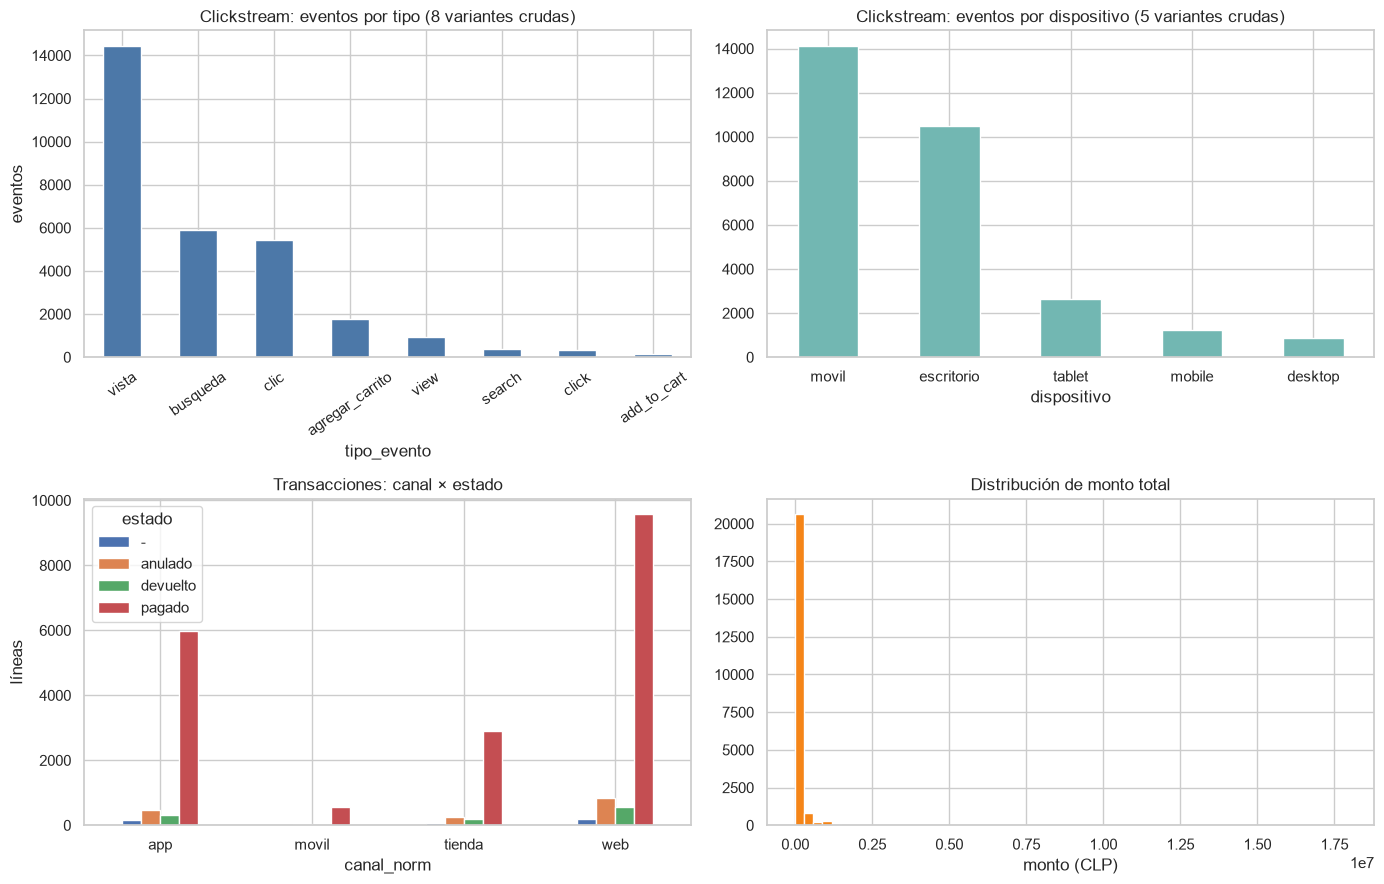

In [14]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1) Clickstream: eventos por tipo (variantes CRUDAS)
ax = axes[0, 0]
tipos = raw["clickstream"]["tipo_evento"].str.strip().str.lower()
n_tipos = tipos.nunique()
tipos.value_counts().plot(kind="bar", ax=ax, color="#4C78A8")
ax.set_title(f"Clickstream: eventos por tipo ({n_tipos} variantes crudas)")
ax.set_ylabel("eventos")
ax.tick_params(axis="x", rotation=35)

# 2) Clickstream: dispositivo
ax = axes[0, 1]
disp = raw["clickstream"]["dispositivo"].str.strip().str.lower()
n_disp = disp.nunique()
disp.value_counts().plot(kind="bar", ax=ax, color="#72B7B2")
ax.set_title(f"Clickstream: eventos por dispositivo ({n_disp} variantes crudas)")
ax.tick_params(axis="x", rotation=0)

# 3) Transacciones: canal × estado
ax = axes[1, 0]
pd.crosstab(tx["canal_norm"], tx["estado"]).plot(kind="bar", ax=ax)
ax.set_title("Transacciones: canal × estado")
ax.set_ylabel("líneas")
ax.tick_params(axis="x", rotation=0)

# 4) Distribución de monto total
ax = axes[1, 1]
monto = intentar_monto(tx["total"]).dropna()
ax.hist(monto, bins=60, color="#F58518")
ax.set_title("Distribución de monto total")
ax.set_xlabel("monto (CLP)")

plt.tight_layout()
plt.show()


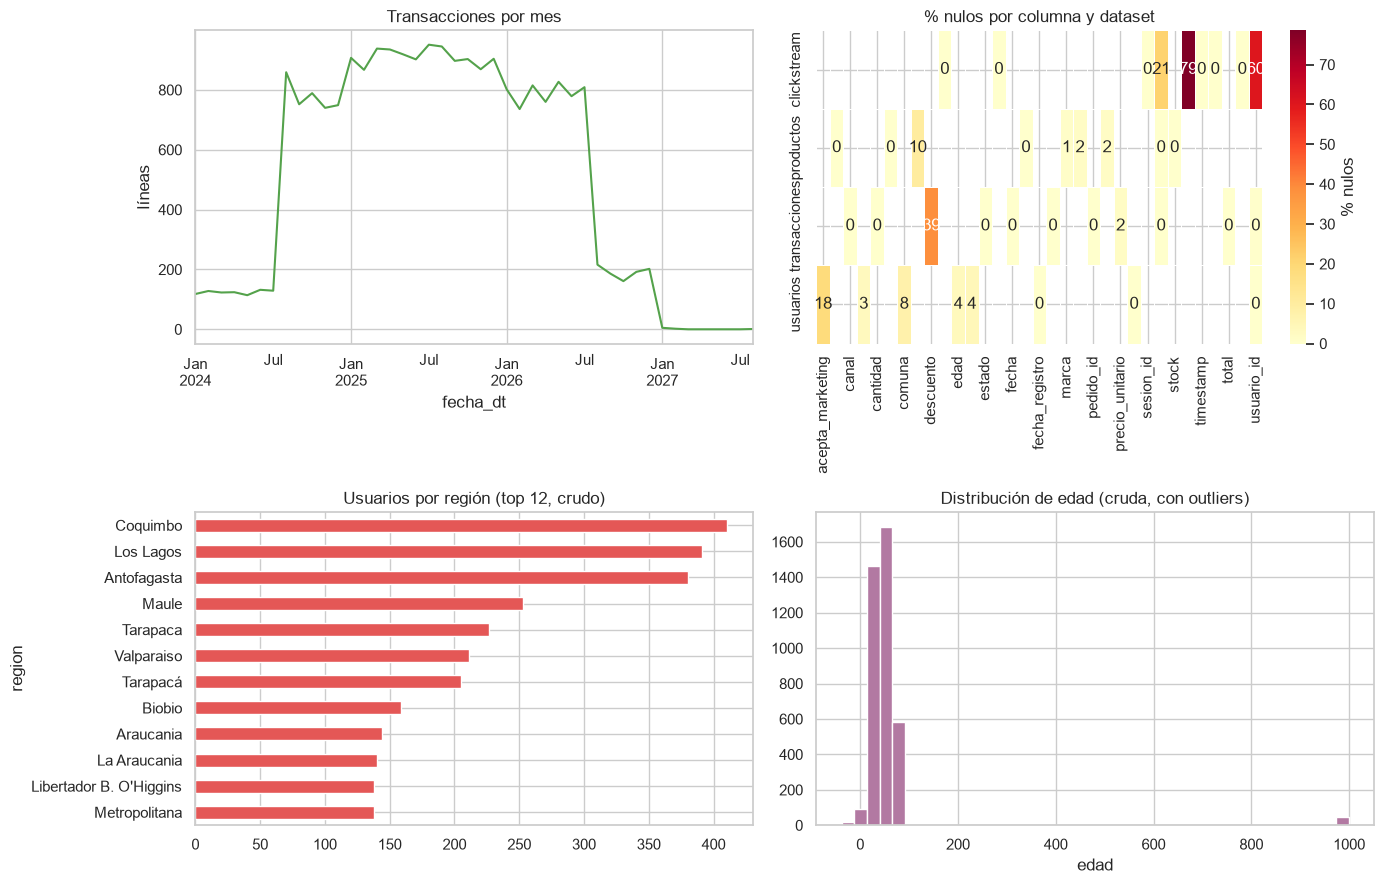

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1) Transacciones por mes (parser multi-formato de la sección 4)
ax = axes[0, 0]
tx.set_index("fecha_dt").resample("ME").size().plot(ax=ax, color="#54A24B")
ax.set_title("Transacciones por mes")
ax.set_ylabel("líneas")

# 2) Usuarios por región (nombres CRUDOS: nótese la fragmentación)
ax = axes[1, 0]
regiones = raw["usuarios"]["region"].str.strip().str.title().value_counts().head(12)
regiones.sort_values().plot(kind="barh", ax=ax, color="#E45756")
ax.set_title("Usuarios por región (top 12, crudo)")

# 3) Edad: incluye valores inválidos (-38 a 999)
ax = axes[1, 1]
edad = pd.to_numeric(raw["usuarios"]["edad"], errors="coerce").dropna()
ax.hist(edad, bins=40, color="#B279A2")
ax.set_title("Distribución de edad (cruda, con outliers)")
ax.set_xlabel("edad")

# 4) Mapa de calor de % nulos por columna y dataset
ax = axes[0, 1]
nulos = pd.DataFrame({n: df.isna().mean() * 100 for n, df in raw.items()}).T
sns.heatmap(nulos, annot=True, fmt=".0f", cmap="YlOrRd", ax=ax,
            cbar_kws={"label": "% nulos"}, linewidths=0.5)
ax.set_title("% nulos por columna y dataset")

plt.tight_layout()
plt.show()


## 9. Limpieza y normalización

A partir de los hallazgos de las secciones 3–6. `raw` queda intacto;
toda transformación vive en `clean`:

- **Texto**: `strip` + `lower` + sin tildes, luego mapeo a valores
  canónicos. Cada `.map()` está envuelto en `mapear()`, que reporta
  los valores no presentes en el diccionario (evita que datos
  desaparezcan en silencio).
- **Booleanos**: `true/1/Si/TRUE` → `True`; `false/0/No` → `False`
- **Fechas**: `intentar_fecha_mixto()` (multi-formato, a UTC).
  ⚠️ Los naive se interpretan como UTC; usa
  `.dt.tz_convert("America/Santiago")` si necesitas hora local.
- **Montos**: `intentar_monto()` interpreta formato CLP
  (`$18.703` = 18703) y detecta posibles decimales (no hay: ver
  assert al final).
- **`total_difiere`**: solo se calcula en filas verificables
  (`total_verificable`); las demás quedan en `False` con la marca.
- **Duplicados**: marcados (`es_duplicado`, `usuario_id_repetido`),
  **no borrados**. Antes de joins, deduplicar `usuarios` por
  `usuario_id` (criterio: registro más antiguo) y decidir con el
  negocio qué hacer con las filas marcadas.
- **Flags de calidad** (señales para revisar, **no** para borrar a
  ciegas): `total_difiere`, `es_devolucion`, `stock_negativo`,
  `edad_invalida`.


In [16]:
# ---------- helpers de texto ----------
def sin_tildes(x):
    if not isinstance(x, str):
        return x
    return "".join(c for c in unicodedata.normalize("NFKD", x) if not unicodedata.combining(c))

def normalizar_texto(s):
    """strip + lower + sin tildes: 'Biobío'/'BIOBIO'/'Bio-Bio' -> 'biobio'."""
    return s.str.strip().str.lower().map(sin_tildes)

# ---------- mapeo con control de valores no mapeados ----------
resumen_mapeo = []

def mapear(s, mapping, nombre_col):
    """Aplica un diccionario y reporta por separado:
    - valores que el diccionario mapea explícitamente a None
      (normalización deliberada, ej. "-" o "unknown")
    - valores NO presentes en el diccionario (desaparición
      silenciosa: generarían NaN sin querer). Debe quedar vacío.
    """
    nulos_antes = int(s.isna().sum())
    mapeado = s.map(mapping)
    nulos_despues = int(mapeado.isna().sum())
    a_null = {k for k, v in mapping.items() if v is None}
    nulos_intencionales = int(s.isin(a_null).sum())
    sin_mapear = sorted(
        s.loc[mapeado.isna() & s.notna() & ~s.isin(a_null)]
        .astype(str).unique().tolist())
    resumen_mapeo.append({
        "columna": nombre_col,
        "nulos_antes": nulos_antes,
        "nuevos_nulos": nulos_despues - nulos_antes,
        "mapeados_a_null": nulos_intencionales,
        "sin_mapear": ", ".join(sin_mapear) if sin_mapear else "",
    })
    return mapeado

# ---------- diccionarios de mapeo ----------
MAP_BOOL = {"true": True, "1": True, "si": True,
            "false": False, "0": False, "no": False}

MAP_TIPO_EVENTO = {"vista": "vista", "view": "vista",
                   "clic": "clic", "click": "clic",
                   "busqueda": "busqueda", "search": "busqueda",
                   "agregar_carrito": "agregar_carrito", "add_to_cart": "agregar_carrito"}

MAP_DISPOSITIVO = {"escritorio": "escritorio", "desktop": "escritorio",
                   "movil": "movil", "mobile": "movil", "tablet": "tablet"}

MAP_CANAL = {"app": "app", "web": "web", "tienda": "tienda", "movil": "movil"}

MAP_ESTADO = {"pagado": "pagado", "devuelto": "devuelto", "anulado": "anulado",
              "-": None}

MAP_CATEGORIA = {"notebooks": "notebooks", "monitores": "monitores", "redes": "redes",
                 "perifericos": "perifericos", "audio": "audio", "almacenamiento": "almacenamiento",
                 "gaming": "gaming", "componentes": "componentes", "cables": "cables",
                 "cables y adaptadores": "cables", "smartphones": "smartphones"}

MAP_REGION = {
    "antofagasta": "Antofagasta",
    "araucania": "Araucania", "la araucania": "Araucania",
    "biobio": "Biobio", "bio-bio": "Biobio", "bio bio": "Biobio",
    "coquimbo": "Coquimbo",
    "del maule": "Maule", "maule": "Maule",
    "los lagos": "Los Lagos",
    "libertador b. o'higgins": "O'Higgins", "o'higgins": "O'Higgins", "ohiggins": "O'Higgins",
    "metropolitana": "Metropolitana", "rm": "Metropolitana",
    "region metropolitana": "Metropolitana", "r. metropolitana": "Metropolitana",
    "tarapaca": "Tarapaca",
    "valparaiso": "Valparaiso", "v region": "Valparaiso",
}

MAP_CANAL_CAPTACION = {"organico": "organico", "pagado": "pagado", "referido": "referido",
                       "email": "email", "directo": "directo", "unknown": None}

clean = {}

# ---------- clickstream ----------
cs = raw["clickstream"].copy()
cs["tipo_evento"] = mapear(normalizar_texto(cs["tipo_evento"]), MAP_TIPO_EVENTO, "clickstream.tipo_evento")
cs["dispositivo"] = mapear(normalizar_texto(cs["dispositivo"]), MAP_DISPOSITIVO, "clickstream.dispositivo")
cs["timestamp"] = intentar_fecha_mixto(cs["timestamp"])
cs["es_duplicado"] = cs.duplicated()
clean["clickstream"] = cs

# ---------- productos ----------
pr = raw["productos"].copy()
pr["categoria"] = mapear(normalizar_texto(pr["categoria"]), MAP_CATEGORIA, "productos.categoria")
pr["marca"] = pr["marca"].str.strip().replace({"N/D": None})
pr["activo"] = mapear(normalizar_texto(pr["activo"]), MAP_BOOL, "productos.activo")
pr["precio_lista"] = intentar_monto(pr["precio_lista"])
pr["costo"] = intentar_monto(pr["costo"])
pr["stock"] = pd.to_numeric(pr["stock"], errors="coerce")
pr["fecha_alta"] = intentar_fecha_mixto(pr["fecha_alta"])
pr["stock_negativo"] = pr["stock"] < 0
pr["es_duplicado"] = pr.duplicated()
clean["productos"] = pr

# ---------- transacciones ----------
tx_c = raw["transacciones"].copy()
tx_c["canal"] = mapear(normalizar_texto(tx_c["canal"]), MAP_CANAL, "transacciones.canal")
tx_c["estado"] = mapear(normalizar_texto(tx_c["estado"]), MAP_ESTADO, "transacciones.estado")
tx_c["fecha"] = intentar_fecha_mixto(tx_c["fecha"])
tx_c["cantidad"] = pd.to_numeric(tx_c["cantidad"], errors="coerce")
tx_c["precio_unitario"] = intentar_monto(tx_c["precio_unitario"])
tx_c["descuento"] = intentar_monto(tx_c["descuento"]).fillna(0)
tx_c["total"] = intentar_monto(tx_c["total"])
tx_c["es_devolucion"] = tx_c["cantidad"] < 0
# total_difiere solo sobre filas verificables (total, cantidad y precio presentes)
tx_c["total_verificable"] = tx_c[["cantidad", "precio_unitario", "total"]].notna().all(axis=1)
tx_c["total_esperado"] = tx_c["cantidad"] * tx_c["precio_unitario"] - tx_c["descuento"]
tx_c["total_difiere"] = ((tx_c["total"] - tx_c["total_esperado"]).abs() > 1) & tx_c["total_verificable"]
tx_c["es_duplicado"] = tx_c.duplicated()
clean["transacciones"] = tx_c

# ---------- usuarios ----------
us_c = raw["usuarios"].copy()
us_c["region"] = mapear(normalizar_texto(us_c["region"]), MAP_REGION, "usuarios.region")
us_c["comuna"] = us_c["comuna"].str.strip().str.title()
us_c["canal_captacion"] = mapear(normalizar_texto(us_c["canal_captacion"]), MAP_CANAL_CAPTACION, "usuarios.canal_captacion")
us_c["email_valido"] = mapear(normalizar_texto(us_c["email_valido"]), MAP_BOOL, "usuarios.email_valido")
us_c["acepta_marketing"] = mapear(normalizar_texto(us_c["acepta_marketing"]), MAP_BOOL, "usuarios.acepta_marketing")
us_c["edad"] = pd.to_numeric(us_c["edad"], errors="coerce")
us_c["edad_invalida"] = ~us_c["edad"].between(1, 100)
us_c["fecha_registro"] = intentar_fecha_mixto(us_c["fecha_registro"])
us_c["usuario_id_repetido"] = us_c["usuario_id"].duplicated()
clean["usuarios"] = us_c

# ---------- confirmación: montos sin decimales (formato CLP entero) ----------
# Si hubiera decimales, intentar_monto los reporta al parsear y este
# assert falla.
patron_decimal = r"^\s*-?\$?\d+[.,]\d{1,2}\s*$"
cols_monto = {"productos": ["precio_lista", "costo"],
              "transacciones": ["precio_unitario", "descuento", "total"]}
con_decimal = []
for nombre, cols in cols_monto.items():
    for c in cols:
        con_decimal += raw[nombre].loc[raw[nombre][c].str.match(patron_decimal, na=False), c].tolist()
assert not con_decimal, f"Montos con decimales detectados: {con_decimal[:5]}"
print("Confirmado: ningún monto tiene decimales (formato CLP entero).")

for nombre, df in clean.items():
    print(f"=== {nombre} ===")
    print(df.dtypes.to_string(), "\n")


Confirmado: ningún monto tiene decimales (formato CLP entero).
=== clickstream ===
evento_id                           str
sesion_id                           str
usuario_id                          str
timestamp           datetime64[us, UTC]
tipo_evento                         str
sku                                 str
termino_busqueda                    str
dispositivo                         str
user_agent                          str
es_duplicado                       bool 

=== productos ===
sku                               str
nombre                            str
categoria                         str
marca                          object
precio_lista                  float64
costo                         float64
stock                         float64
activo                           bool
fecha_alta        datetime64[us, UTC]
stock_negativo                   bool
es_duplicado                     bool 

=== transacciones ===
pedido_id                            str
linea         

In [17]:
# ---------- resumen del mapeo: valores no mapeados ----------
display(pd.DataFrame(resumen_mapeo))

# ---------- valores normalizados ----------
print("Regiones:", sorted(clean["usuarios"]["region"].dropna().unique()))
print("Categorías:", sorted(clean["productos"]["categoria"].dropna().unique()))
print("Tipos de evento:", sorted(clean["clickstream"]["tipo_evento"].dropna().unique()))
print("Dispositivos:", sorted(clean["clickstream"]["dispositivo"].dropna().unique()))
print("Canales:", sorted(clean["transacciones"]["canal"].dropna().unique()))
print("Estados:", sorted(clean["transacciones"]["estado"].dropna().unique()))
print()
print("Rangos de fechas (UTC):")
for nombre, col in [("clickstream", "timestamp"), ("transacciones", "fecha"),
                    ("productos", "fecha_alta"), ("usuarios", "fecha_registro")]:
    s = clean[nombre][col]
    print(f"  {nombre}.{col}: {s.min()} -> {s.max()} | NaT: {int(s.isna().sum())}")
print()
print("Registros marcados (señales, no borrados):")
print(f"  transacciones con total ≠ cant×precio−desc: {int(clean['transacciones']['total_difiere'].sum())}"
      f" (no verificables: {int((~clean['transacciones']['total_verificable']).sum())})")
print(f"  transacciones con cantidad negativa (devolución): {int(clean['transacciones']['es_devolucion'].sum())}")
print(f"  productos con stock negativo: {int(clean['productos']['stock_negativo'].sum())} ({clean['productos']['stock_negativo'].mean() * 100:.1f}%)")
print(f"  usuarios con edad fuera de [1, 100]: {int(clean['usuarios']['edad_invalida'].sum())} ({clean['usuarios']['edad_invalida'].mean() * 100:.1f}%)")
print(f"  transacciones con estado '-' (desconocido): {int(clean['transacciones']['estado'].isna().sum())}")
print()
print("Duplicados marcados (no borrados):")
print(f"  clickstream: {int(clean['clickstream']['es_duplicado'].sum())}")
print(f"  transacciones: {int(clean['transacciones']['es_duplicado'].sum())}")
print(f"  productos: {int(clean['productos']['es_duplicado'].sum())}")
print(f"  usuarios con usuario_id repetido: {int(clean['usuarios']['usuario_id_repetido'].sum())}")


,columna,nulos_antes,nuevos_nulos,mapeados_a_null,sin_mapear
0,clickstream.tipo_evento,0,0,0,
1,clickstream.dispositivo,0,0,0,
2,productos.categoria,0,0,0,
3,productos.activo,0,0,0,
4,transacciones.canal,0,0,0,
5,transacciones.estado,0,453,453,
6,usuarios.region,0,0,0,
7,usuarios.canal_captacion,129,208,208,
8,usuarios.email_valido,180,0,0,
9,usuarios.acepta_marketing,733,0,0,


Regiones: ['Antofagasta', 'Araucania', 'Biobio', 'Coquimbo', 'Los Lagos', 'Maule', 'Metropolitana', "O'Higgins", 'Tarapaca', 'Valparaiso']
Categorías: ['almacenamiento', 'audio', 'cables', 'componentes', 'gaming', 'monitores', 'notebooks', 'perifericos', 'redes', 'smartphones']
Tipos de evento: ['agregar_carrito', 'busqueda', 'clic', 'vista']
Dispositivos: ['escritorio', 'movil', 'tablet']
Canales: ['app', 'movil', 'tienda', 'web']
Estados: ['anulado', 'devuelto', 'pagado']

Rangos de fechas (UTC):
  clickstream.timestamp: 2024-01-08 08:13:22+00:00 -> 2026-12-08 01:55:59+00:00 | NaT: 0
  transacciones.fecha: 2024-01-08 01:28:52+00:00 -> 2027-08-02 00:00:00+00:00 | NaT: 0
  productos.fecha_alta: 2019-01-01 00:00:00+00:00 -> 2026-12-05 00:00:00+00:00 | NaT: 0
  usuarios.fecha_registro: 2019-01-01 00:00:00+00:00 -> 2027-10-02 00:00:00+00:00 | NaT: 0

Registros marcados (señales, no borrados):
  transacciones con total ≠ cant×precio−desc: 2244 (no verificables: 440)
  transacciones con can

## 10. Resumen de conclusiones

### Volumen
- **usuarios**: 4.026 registros · **transacciones**: 22.187 líneas (17.146 pedidos) · **productos**: 1.531 · **clickstream**: 29.340 eventos en 6.000 sesiones

### 🔎 Variable objetivo: NO existe (descubierta por análisis)
Ninguno de los 4 datasets tiene columna de fraude/etiqueta, y tampoco la definen el README, el historial git, ni `app/`, `tests/` o `datos/preparar.py` (vacíos). El caso es un dataset **sintético con anomalías inyectadas**:

| Señal descubierta | Líneas/eventos | % |
|---|---|---|
| `total ≠ cantidad × precio − descuento` (aritmética imposible; 440 líneas no verificables por precio nulo) | 2.244 | 10,1% |
| compra **anterior** al registro del usuario (865 usuarios, hasta 1.301 días antes) | 3.147 | 14,2% |
| `usuario_id` placeholder ("invitado" 94, "UNKNOWN" 93, vacío 93) | 280 | 1,3% |
| usuario huérfano (transacciona sin ficha en `usuarios.csv`) | 663 | 3,0% |
| total negativo / cantidad negativa | 130 / 234 | 0,6% / 1,1% |
| bots en clickstream (Scrapy, curl, Googlebot, SemrushBot, AhrefsBot, python-requests) | 1.791 ev. | 6,1% |

**Etiqueta derivada propuesta** (nivel línea de transacción, construida en la sección 7):

```
sospechoso = n_senales ≥ 2, con n_senales = total_difiere + total_negativo
             + cantidad_negativa + compra_antes_registro
             + usuario_huerfano + usuario_id_placeholder
```

- ≥1 señal: 5.699 líneas (25,7%) → demasiado amplio
- **≥2 señales (`sospechoso`): 902 líneas (4,1%)** → tasa base realista para fraude
- ≥3 señales: 91 líneas
- **Alternativa**: si el objetivo de negocio es el resultado del pedido, `estado` es la etiqueta limpia (pagado 85,7% / anulado 7,3% / devuelto 5,0% / "-" 2,0%).

⚠️ Toda etiqueta derivada es un **proxy**: la etiqueta real de fraude (ej. chargebacks) solo la tiene el negocio. **Pendiente confirmación.**

### Calidad de datos (arreglar antes de modelar)
1. **Fechas con 4 formatos** (ISO, ISO con zona horaria, `dd/mm/aaaa`, `dd-mm-aaaa`): con `format="mixed"` el **100% parsea** (el parser ingenuo fallaba en 13k–16k). ⚠️ Todo queda en UTC.
2. **Montos en formato chileno** (`$18.703` = 18.703, punto de miles): 100% parseables si se interpreta bien, y sin decimales (confirmado con assert en la sección 9). Un parser ingenuo los lee como decimales y **rompe la verificación de totales**.
3. **Valores fuera de rango**: edad de −38 a 999 (297, 7,4%), stock negativo (38, 2,5%).
4. **Categóricas fragmentadas** (normalizadas en `clean`): regiones 33→10, categorías 20→10, tipo_evento 14→4, canal 7→4, booleanos 7→2.
5. **Estado desconocido `-`**: 453 líneas (2,0%).
6. **Duplicados marcados, no borrados**: 263 eventos, 186 líneas de transacciones, 31 productos y 26 `usuario_id` repetidos en `usuarios.csv`.
7. **Integridad referencial**: 297 usuarios con transacciones sin ficha; 60,2% de eventos clickstream sin `usuario_id` (tráfico anónimo).
8. **Nulos relevantes**: `descuento` 39% (tratado como 0 en `clean`), `usuario_id` clickstream 60%, `termino_busqueda` 79% (esperable: solo aplica a búsquedas), `edad` 3,5%.

### ⚠️ Riesgo de circularidad y leakage
- **Circularidad de la etiqueta derivada**: `sospechoso` se define con estas mismas señales. Si se usan como features, el modelo **aprende la regla, no detecta fraude** (es trivial: memoriza la fórmula). Salidas posibles:
  1. **Excluir** las señales usadas en la etiqueta del conjunto de features (y cualquier columna derivada de ellas);
  2. Usar la etiqueta derivada solo como **regla baseline**, no como target de ML;
  3. **Conseguir la etiqueta real** (chargebacks, reportes de fraude) y reentrenar.
- Sin etiqueta confirmada no se puede evaluar a fondo. Al definirla, ojo con columnas que solo existirían *después* del fraude (ej. `estado`, `descuento`).

### Recomendaciones
- **No borrar** outliers, negativos ni duplicados a ciegas: en detección de fraude son señal. Marcar y revisar.
- **Antes de joins**, deduplicar `usuarios` por `usuario_id` (criterio usado: registro más antiguo) y decidir el tratamiento de las filas marcadas como `es_duplicado`.
- Validaciones en ingest: formato único de fecha, montos numéricos (formato CLP), rango de edad, regla de cálculo de `total`.
- Resolver `usuario_id` anónimo/placeholder o aceptar cobertura parcial por usuario.
- Persistir `clean/` como capa intermedia antes del feature engineering.
